# Chapitre 4 - Exercices 4.1 à 4.5

Ce notebook traite cinq exercices sur les **critères d'évaluation** et la **sélection de
modèle** :

- **4.1** : QCM, battre le hasard et résister aux permutations (calcul + mini-lab) ;
- **4.2** : un vérificateur de cohérence factuelle de bout en bout (mini-lab NLI) ;
- **4.3** : étendre IFEval avec de nouvelles contraintes vérifiables (mini-lab) ;
- **4.4** : un budget de latence, du calcul à la mesure (calcul + mesure GPU) ;
- **4.5** : choisir un modèle sous contraintes pour un hôpital (raisonnement + calcul).

In [1]:
import os
os.environ.setdefault("HF_HUB_OFFLINE", "1")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from aie.plotting import (set_style, COLORS, INDIGO, TEAL, AMBER, ROSE, VIOLET, SKY, SLATE, GRAY,
                          GREEN, LIGHT, annotate_bars, subtitle, finish)
from aie.diagrams import Diagram
from aie import llm
from aie import ch04_systemes as c4

set_style()
pd.set_option("display.max_colwidth", 90)
llm.seed_everything(0)

## Exercice 4.1 : QCM, battre le hasard et résister aux permutations

**Énoncé.** Un benchmark contient $n$ QCM à 4 options, une seule correcte.

1. Pour $n = 100$, quel score minimal permet d'affirmer, au niveau 5 %, qu'un modèle fait
   mieux que le hasard ? Comparer le calcul exact (binomial) et l'approximation normale.
2. Un modèle a une exactitude réelle de 30 %. Combien de questions faut-il pour que, avec une
   probabilité de 80 %, son score dépasse le seuil de la question 1 ?
3. On adopte une **évaluation circulaire** : une question n'est réussie que si le modèle
   répond juste sous les 4 permutations circulaires des options. Quelle est la ligne de base
   aléatoire ? Mesurer l'exactitude standard et circulaire de Qwen 0.5B et Qwen 1.5B sur le QCM
   du module.

**Rappels.** Section *Domain-Specific Capability* : la ligne de base d'un QCM à $k$ options
est $1/k$ ; les réponses d'un modèle varient avec la présentation des options (Alzahrani et
al., 2024). Le nombre de bonnes réponses d'un devineur suit $\mathcal B(n, 1/4)$ (cours 1,
section 2).

**Solution.**

*1.* On cherche le plus petit $k$ tel que $P(X \geq k) < 0{,}05$ pour $X \sim \mathcal B(100, 0{,}25)$.
Approximation normale : $\mu = 25$, $\sigma = \sqrt{100 \times 0{,}25 \times 0{,}75} \approx 4{,}33$,
donc $k \approx 25 + 1{,}645 \times 4{,}33 \approx 32{,}1$, soit **33 bonnes réponses** (33 %).

*2.* Il faut que $P(Y \geq k_n) \geq 0{,}8$ avec $Y \sim \mathcal B(n, 0{,}3)$ et $k_n$ le seuil de
la question 1 pour $n$ questions. En approximation normale :
$$0{,}25\,n + 1{,}645\sqrt{n\cdot 0{,}1875} \;\leq\; 0{,}3\,n - 0{,}842\sqrt{n\cdot 0{,}21}
\;\Longrightarrow\; \sqrt n \geq \frac{1{,}645\sqrt{0{,}1875} + 0{,}842\sqrt{0{,}21}}{0{,}05}
\approx 22{,}0,$$
soit **environ 480 questions** (le calcul exact, ci-dessous, donne un peu plus) : détecter un
modèle à peine meilleur que le hasard coûte cher.

*3.* Un devineur doit réussir 4 tirages indépendants à 1/4 : la ligne de base circulaire est
$(1/4)^4 \approx 0{,}4\,\%$. L'évaluation circulaire est bien plus exigeante : elle pénalise les
bonnes réponses « chanceuses » et le biais de position.

1. seuil exact pour n=100 : 33 bonnes réponses ; approximation normale : 32.1


2. nombre de questions pour 80 % de puissance (calcul exact) : 520


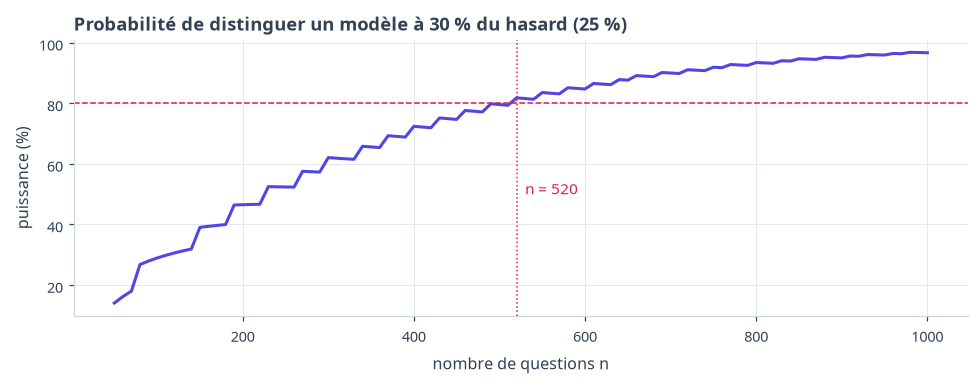

In [2]:
def k_crit(n, p0=0.25, alpha=0.05):
    return next(k for k in range(n + 1) if c4.binom_sf(k, n, p0) < alpha)

k100 = k_crit(100)
print(f"1. seuil exact pour n=100 : {k100} bonnes réponses ; approximation normale : "
      f"{25 + 1.645 * np.sqrt(100 * 0.1875):.1f}")
ns = np.arange(50, 1001, 10)
power = np.array([c4.binom_sf(k_crit(n), n, 0.30) for n in ns])
n80 = ns[np.argmax(power >= 0.8)]
print(f"2. nombre de questions pour 80 % de puissance (calcul exact) : {n80}")

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(ns, power * 100, color=INDIGO)
ax.axhline(80, color=ROSE, ls="--", lw=1); ax.axvline(n80, color=ROSE, ls=":", lw=1)
ax.text(n80 + 10, 50, f"n = {n80}", color=ROSE)
ax.set_xlabel("nombre de questions n"); ax.set_ylabel("puissance (%)")
ax.set_title("Probabilité de distinguer un modèle à 30 % du hasard (25 %)")
plt.tight_layout(); plt.show()

La courbe exacte présente de petites dents de scie (le seuil $k_n$ est entier) mais confirme
l'ordre de grandeur de l'approximation normale. **Vérification expérimentale** de la question 3.

In [3]:
def circular_eval(model_id):
    std, circ = [], []
    for it in c4.MCQ_ITEMS:
        oks = []
        for s in range(4):
            order = [(j + s) % 4 for j in range(4)]
            prompt, gold = c4.format_mcq(it, "standard", order)
            oks.append(int(np.argmax(c4.letter_logits(prompt, model_id))) == gold)
        std.append(oks[0]); circ.append(all(oks))
    return np.mean(std), np.mean(circ)

res = {}
res["Qwen 0.5B"] = circular_eval(llm.SMALL)
res["Qwen 1.5B"] = circular_eval(llm.MEDIUM)
llm.free_gpu()
tab = pd.DataFrame({k: dict(standard=v[0], circulaire=v[1]) for k, v in res.items()}).T
tab.loc["hasard"] = [0.25, 0.25**4]
(tab * 100).round(1)

,standard,circulaire
Qwen 0.5B,65.4,38.5
Qwen 1.5B,92.3,88.5
hasard,25.0,0.4


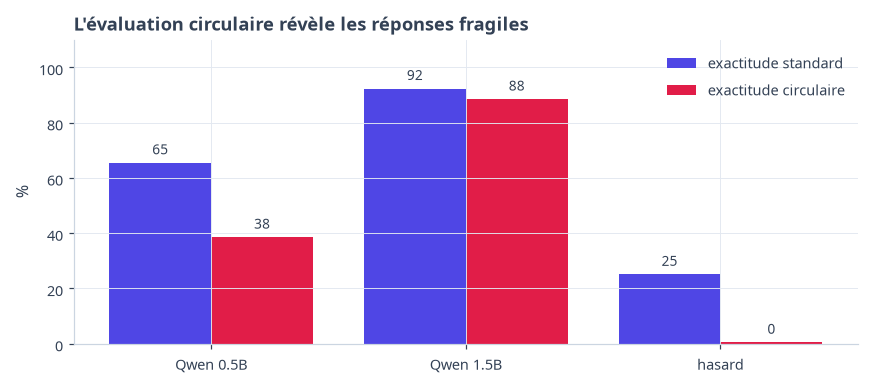

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(len(tab))
ax.bar(x - 0.2, tab.standard * 100, 0.4, color=INDIGO, label="exactitude standard")
ax.bar(x + 0.2, tab.circulaire * 100, 0.4, color=ROSE, label="exactitude circulaire")
annotate_bars(ax, "{:.0f}")
ax.set_xticks(x, tab.index); ax.set_ylabel("%"); ax.set_ylim(0, 110); ax.legend()
ax.set_title("L'évaluation circulaire révèle les réponses fragiles")
plt.tight_layout(); plt.show()

L'écart entre exactitude standard et circulaire mesure la part de réponses qui ne tiennent
pas à une simple permutation des options : il est nettement plus grand pour le petit modèle.
Avec seulement 26 questions, ces chiffres restent indicatifs (la question 2 montre qu'il en
faudrait des centaines pour des conclusions fines).

> **À retenir.** Un score de QCM se juge contre $1/k$ avec un test binomial, et il faut
> beaucoup de questions pour détecter un petit écart au hasard. L'évaluation circulaire
> (ligne de base $(1/k)^k$) filtre les réponses chanceuses et le biais de position.

## Exercice 4.2 : Un vérificateur de cohérence factuelle de bout en bout

**Énoncé.** On veut noter des résumés de la fiche de la médiathèque (`c4.FACT_CONTEXT`).

1. Faire produire par Qwen 0.5B un résumé en trois phrases de la fiche.
2. Construire deux variantes **corrompues** de ce résumé : une où l'on remplace l'horaire de
   fermeture par un faux, une où l'on ajoute une phrase invérifiable.
3. Noter les trois résumés phrase par phrase par NLI, puis agréger par la moyenne et par le
   minimum de $p_{\text{impl}}$. Quelle agrégation sépare le mieux les résumés ?
4. Que se passe-t-il si une phrase mêle un fait correct et un fait faux ? Proposer un remède.

**Rappels.** Section *Factual consistency* : cohérence locale = NLI avec le contexte comme
prémisse ; agrégations $\text{score}_{\text{moyen}} = \frac1m\sum_i p_{\text{impl}}(C, h_i)$ et
$\text{score}_{\min} = \min_i p_{\text{impl}}(C, h_i)$ (cours 1, section 5). SAFE décompose la
réponse en **faits atomiques** avant de vérifier.

**Solution.** *1-2.* On génère le résumé de façon gloutonne, puis on fabrique les variantes
à la main (c'est ainsi qu'on construit des jeux de test pour un vérificateur : en injectant
des erreurs **connues**).

In [5]:
resume = llm.chat("Résume cette fiche en trois phrases courtes.\n\n" + c4.FACT_CONTEXT, llm.SMALL,
                  max_new_tokens=120)
print("Résumé de Qwen 0.5B :\n", resume)
variantes = {
    "résumé du modèle": resume,
    "horaire falsifié": "La médiathèque Jules-Verne se trouve à Nantes. Elle est ouverte du mardi au samedi jusqu'à 21 h. "
                        "Chaque abonné peut emprunter 10 documents.",
    "ajout invérifiable": "La médiathèque Jules-Verne se trouve à Nantes. Elle est ouverte du mardi au samedi. "
                          "Elle accueille chaque année un festival de bande dessinée.",
    "résumé fidèle (témoin)": "La médiathèque Jules-Verne a ouvert en 2012 à Nantes. Elle est fermée le dimanche et le lundi. "
                              "L'inscription est gratuite pour les mineurs.",
}

Résumé de Qwen 0.5B :
 La médiathèque Jules-Verne offre des heures d'ouverture de 10h à 19h tous les jours, avec un coût de 15€ par an pour les enfants de 18 ans.


*3.* On note chaque phrase et on agrège.

In [6]:
rows, detail = [], {}
for k, v in variantes.items():
    df = c4.factual_consistency(c4.FACT_CONTEXT, v)
    detail[k] = df
    rows.append(dict(résumé=k, phrases=len(df), moyenne=df.implication.mean(), minimum=df.implication.min(),
                     contradictions=(df.verdict == "contradiction").sum()))
agg = pd.DataFrame(rows).set_index("résumé")
agg.round(3)

,phrases,moyenne,minimum,contradictions
résumé,,,,
résumé du modèle,1,0.006,0.006,1
horaire falsifié,3,0.666,0.001,1
ajout invérifiable,3,0.666,0.000,0
résumé fidèle (témoin),3,0.996,0.994,0


In [7]:
detail["horaire falsifié"].round(3)

,affirmation,implication,neutre,contradiction,verdict
0,La médiathèque Jules-Verne se trouve à Nantes.,0.999,0.000,0.000,implication
1,Elle est ouverte du mardi au samedi jusqu'à 21 h.,0.001,0.001,0.998,contradiction
2,Chaque abonné peut emprunter 10 documents.,0.997,0.002,0.001,implication


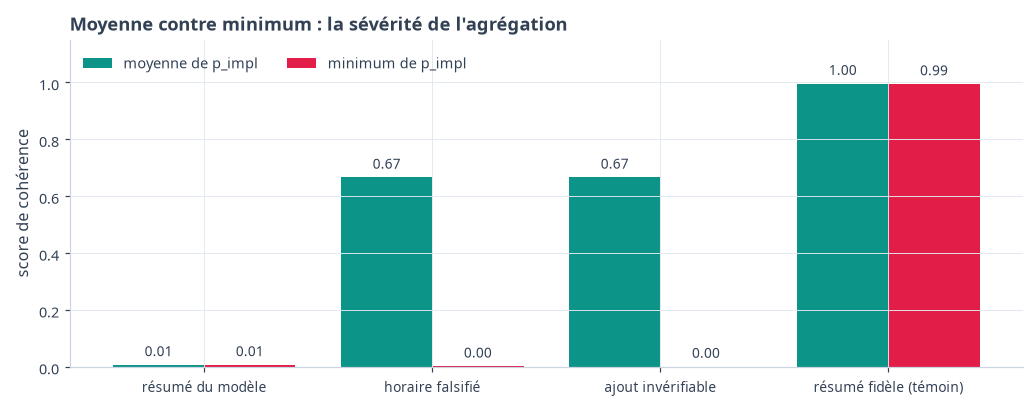

In [8]:
fig, ax = plt.subplots(figsize=(9.5, 3.8))
x = np.arange(len(agg))
ax.bar(x - 0.2, agg.moyenne, 0.4, color=TEAL, label="moyenne de p_impl")
ax.bar(x + 0.2, agg.minimum, 0.4, color=ROSE, label="minimum de p_impl")
annotate_bars(ax, "{:.2f}")
ax.set_xticks(x, agg.index, fontsize=9); ax.set_ylim(0, 1.15); ax.set_ylabel("score de cohérence")
ax.legend(loc="upper left", ncol=2); ax.set_title("Moyenne contre minimum : la sévérité de l'agrégation")
plt.tight_layout(); plt.show()

Le minimum sépare nettement les résumés fautifs (une seule phrase fausse ou invérifiable fait
chuter le score près de 0) du témoin fidèle ; la moyenne dilue l'erreur parmi les phrases
correctes (environ 2/3 pour un résumé de 3 phrases dont une fausse). Pour une application où
une seule hallucination est inacceptable, le minimum est le bon choix. Le résumé du petit
modèle lui-même peut contenir des approximations : son score se lit sur la sortie ci-dessus.

*4.* Une phrase composée (« ouverte en 2012 et fermée le mardi ») mélange un fait vrai et un
faux : le NLI doit trancher globalement, et la contradiction peut être masquée ou, à
l'inverse, contaminer le fait correct. Vérifions, puis appliquons le remède de SAFE :
décomposer en faits atomiques avant la vérification.

In [9]:
composee = "La médiathèque a ouvert en 2012 et elle est fermée le mardi."
atomes = ["La médiathèque a ouvert en 2012.", "La médiathèque est fermée le mardi."]
p_comp = c4.nli_probs(c4.FACT_CONTEXT, composee)[0]
p_at = c4.nli_probs([c4.FACT_CONTEXT] * 2, atomes)
pd.DataFrame(np.vstack([p_comp, p_at]), index=["phrase composée"] + atomes,
             columns=["implication", "neutre", "contradiction"]).round(3)

,implication,neutre,contradiction
phrase composée,0.001,0.001,0.998
La médiathèque a ouvert en 2012.,0.999,0.001,0.000
La médiathèque est fermée le mardi.,0.001,0.001,0.998


Les faits atomiques donnent des verdicts nets et localisent l'erreur (« fermée le mardi » est
contredit). La décomposition peut se faire par règles (coordinations « et ») ou, comme dans
SAFE, par un LLM chargé de réécrire la réponse en affirmations autonomes.

> **À retenir.** Un vérificateur de cohérence se teste en **injectant des erreurs connues**.
> Agréger par le minimum rend une seule hallucination éliminatoire ; décomposer en faits
> atomiques rend le verdict NLI plus net et localise l'erreur.

## Exercice 4.3 : Étendre IFEval avec de nouvelles contraintes vérifiables

**Énoncé.** Votre application a des contraintes propres que le module ne couvre pas :

- (a) « Réponds entièrement en français » ;
- (b) « Ta réponse doit commencer par le mot {mot} » ;
- (c) « Ta réponse doit comporter {N} sections, chacune commençant par SECTION X » (X = 1, 2...).

1. Écrire un vérificateur pour chacune et le **tester** sur des exemples positifs et négatifs.
2. Construire 6 tâches utilisant ces contraintes et mesurer Qwen 0.5B en strict et en souple.
3. Pour (a), discuter les limites d'un vérificateur fondé sur des mots-outils.

**Rappels.** Section *Instruction-following criteria* : IFEval ne retient que des contraintes
vérifiables par programme ; score strict sur la réponse brute, souple sur ses variantes
(sans première/dernière ligne, sans astérisques). Le livre recommande de construire son propre
banc avec ses propres contraintes (« si vous voulez du YAML, testez le YAML »).

**Solution.** *1.* Pour (a), on compte la proportion de mots-outils français parmi les
mots-outils français et anglais rencontrés : une réponse est jugée française si cette part
dépasse 80 %. Pour (b), on compare le premier mot (sans ponctuation ni markdown). Pour (c), on
cherche les marqueurs `SECTION 1`, `SECTION 2`... dans l'ordre.

In [10]:
import re

FR = {"le", "la", "les", "de", "des", "du", "un", "une", "et", "est", "en", "que", "qui", "pour", "dans",
      "sur", "pas", "il", "elle", "nous", "vous", "avec", "au", "aux", "ce", "cette", "sont", "par", "plus"}
EN = {"the", "of", "and", "is", "to", "in", "that", "it", "for", "on", "with", "as", "are", "this", "be",
      "by", "not", "you", "we", "they", "an", "at", "from", "or", "was", "can", "has", "have"}

def check_francais(r, seuil=0.8):
    mots = re.findall(r"[a-zàâçéèêëîïôûùüÿœ']+", r.lower())
    fr, en = sum(m in FR for m in mots), sum(m in EN for m in mots)
    return fr + en > 0 and fr / (fr + en) >= seuil

def check_premier_mot(r, mot):
    m = re.findall(r"\w+", r.replace("*", ""))
    return bool(m) and m[0].lower() == mot.lower()

def check_sections(r, n):
    nums = [int(x) for x in re.findall(r"SECTION\s+(\d+)", r)]
    return nums == list(range(1, n + 1))

# enregistrement dans le registre du module (sans modifier le fichier) pour profiter de evaluate_ifeval
c4.INSTRUCTION_TYPES["francais"] = ("Réponds entièrement en français.", check_francais)
c4.INSTRUCTION_TYPES["premier_mot"] = ("Ta réponse doit commencer par le mot « {mot} ».", check_premier_mot)
c4.INSTRUCTION_TYPES["sections"] = ("Ta réponse doit comporter {n} sections, chacune commençant par SECTION X (X = 1, 2...).", check_sections)
for k in ["francais", "premier_mot", "sections"]:
    c4.INSTRUCTION_GROUPS[k] = "maison"

tests = [
    ("francais", {}, "Le chat dort sur le canapé et il est content.", "The cat is sleeping on the sofa and it is happy."),
    ("premier_mot", dict(mot="Bonjour"), "**Bonjour**, voici ma réponse.", "Voici ma réponse. Bonjour."),
    ("sections", dict(n=2), "SECTION 1\nIntro\nSECTION 2\nSuite", "SECTION 1\nIntro\nSECTION 3\nSuite"),
]
for kind, params, ok, ko in tests:
    inst = c4.Instruction(kind, params)
    assert inst.check(ok) and not inst.check(ko), kind
print("Les 3 vérificateurs passent leurs tests positifs et négatifs.")

Les 3 vérificateurs passent leurs tests positifs et négatifs.


*2.* Six tâches, générées de façon gloutonne par Qwen 0.5B.

In [11]:
I = c4.Instruction
mes_taches = [
    c4.IFTask("Explique ce qu'est une API.", [I("francais")]),
    c4.IFTask("Donne un conseil pour apprendre une langue.", [I("premier_mot", dict(mot="Conseil"))]),
    c4.IFTask("Présente le recyclage du plastique.", [I("sections", dict(n=2))]),
    c4.IFTask("Explain what a database index is.", [I("francais")]),
    c4.IFTask("Décris le métier de boulanger.", [I("sections", dict(n=3)), I("francais")]),
    c4.IFTask("Écris une phrase d'accueil pour un site web.", [I("premier_mot", dict(mot="Bienvenue")), I("nombre_mots", dict(n=20, relation="au plus"))]),
]
sorties = c4.chat_batch([t.prompt for t in mes_taches], llm.SMALL, max_new_tokens=200)
ev = c4.evaluate_ifeval(mes_taches, sorties)
print(c4.ifeval_summary(ev).round(2).to_dict())
ev.assign(debut=[sorties[t][:70].replace("\n", " / ") for t in ev.tache])

{'prompt strict': 0.67, 'prompt souple': 0.67, 'instruction strict': 0.75, 'instruction souple': 0.75}


,tache,type,groupe,strict,souple,debut
0,0,francais,maison,True,True,Une API (Application Programming Interface) est un outil de communicat
1,1,premier_mot,maison,True,True,"Conseil: Apprenez la langue de manière fluide et régulière, en utilisa"
2,2,sections,maison,False,False,SECTION 1: Recyclage du Plastique / / Le recyclage du plastique est un pr
3,3,francais,maison,True,True,Un index dans une base de données est un élément de structure logique
4,4,sections,maison,False,False,SECTION 1: Le Boulanger : Un Ménage à Table / / Le boulanger est un trava
5,4,francais,maison,True,True,SECTION 1: Le Boulanger : Un Ménage à Table / / Le boulanger est un trava
6,5,premier_mot,maison,True,True,"Bienvenue sur notre site web, où nous vous offrons des informations et"
7,5,nombre_mots,longueur,True,True,"Bienvenue sur notre site web, où nous vous offrons des informations et"


Lecture : la tâche posée en anglais avec la contrainte « réponds en français » teste si le
modèle suit la consigne de langue plutôt que la langue de la question (relire le tableau : la
consigne finale en français suffit souvent). Les sections numérotées sont la contrainte la plus
fragile : le modèle ouvre bien par « SECTION 1 », puis revient à ses habitudes de titres
markdown et oublie la numérotation exigée. Un écart entre strict et souple viendrait de
préambules du type « Voici... » avant le premier mot exigé.

*3.* Le vérificateur de langue par mots-outils est simple et rapide mais : il échoue sur les
réponses très courtes (aucun mot-outil), confond les langues proches (français / italien n'ont
pas les mêmes mots-outils, mais une réponse en espagnol peut ne contenir aucun des mots de
nos deux listes), et accepte une réponse française parsemée de termes techniques anglais (ce
qui est souvent souhaitable). IFEval utilise une bibliothèque de détection de langue ; un
compromis consiste à combiner les deux.

> **À retenir.** Ajouter une contrainte vérifiable demande trois choses : un gabarit de
> consigne, un vérificateur, et des **tests unitaires** positifs et négatifs du vérificateur
> lui-même. Un vérificateur non testé est une source d'erreurs de mesure silencieuses.

## Exercice 4.4 : Un budget de latence, du calcul à la mesure

**Énoncé.** Un assistant de rédaction a un TTFT de 300 ms et un TPOT de 25 ms.

1. Quelle est la latence totale d'une réponse de 400 tokens ?
2. L'exigence dure est « latence totale P90 < 5 s ». Quelle longueur de réponse maximale
   garantit le respect de l'exigence ? Que faire si 10 % des réponses demandent 300 tokens ?
3. En streaming, l'utilisateur lit environ 5 mots par seconde ; en français, on compte
   environ 1,4 token par mot. Quel TPOT maximal évite que l'utilisateur n'attende le texte ?
4. Mesurer TTFT et TPOT de Qwen 0.5B sur notre GPU pour un lot de 1, 8 et 32 requêtes, et
   déterminer la plus grande taille de lot qui respecte TPOT < 30 ms.

**Rappels.** Section *Cost and Latency* et cours 2, section 6 :
$\text{latence} = \text{TTFT} + (n-1)\,\text{TPOT}$. Le TPOT augmente (peu) avec la taille du
lot, tandis que le débit total augmente fortement.

**Solution.**

*1.* $0{,}3 + 399 \times 0{,}025 = 10{,}3$ s.

*2.* $0{,}3 + (n-1) \times 0{,}025 < 5 \iff n < 189$ : au plus **188 tokens**. Si 10 % des
réponses demandent 300 tokens, le P90 se situe à la frontière de ces réponses longues : il faut
soit plafonner la longueur (`max_tokens`, consigne de concision), soit réduire le TPOT (modèle
plus petit, quantification, chapitre 9), soit accepter de redéfinir l'exigence sur le TTFT
plutôt que sur la latence totale (le streaming rend la latence totale moins critique).

*3.* $5 \times 1{,}4 = 7$ tokens/s à lire, soit un TPOT maximal de $1/7 \approx 143$ ms. Notre
TPOT de 25 ms est 6 fois plus rapide que la lecture : la latence totale importe moins que le
TTFT pour l'expérience ressentie.

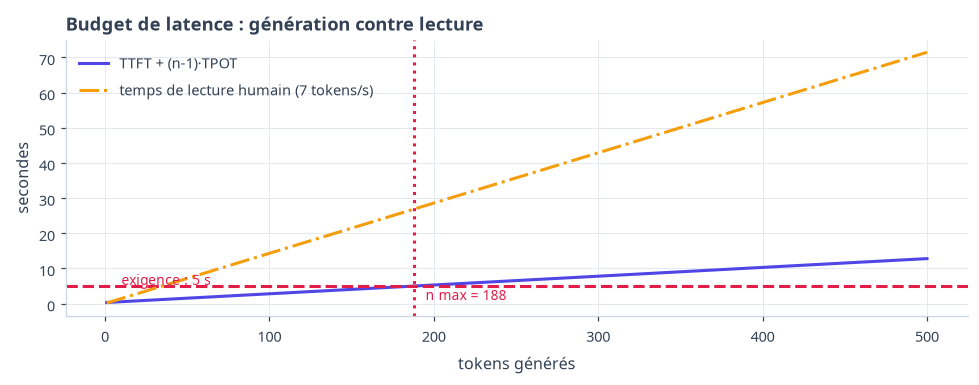

In [12]:
n = np.arange(1, 501)
lat = c4.latency_model(n, 0.3, 0.025)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(n, lat, color=INDIGO, label="TTFT + (n-1)·TPOT")
ax.axhline(5, color=ROSE, ls="--"); ax.text(10, 5.3, "exigence : 5 s", color=ROSE, fontsize=9)
ax.axvline(188, color=ROSE, ls=":"); ax.text(195, 1, "n max = 188", color=ROSE, fontsize=9)
ax.plot(n, n / 7, color=AMBER, ls="-.", label="temps de lecture humain (7 tokens/s)")
ax.set_xlabel("tokens générés"); ax.set_ylabel("secondes"); ax.legend()
ax.set_title("Budget de latence : génération contre lecture")
plt.tight_layout(); plt.show()

La génération (bleu) reste toujours sous le temps de lecture (ambre) : en streaming,
l'utilisateur ne rattrape jamais le modèle. *4.* **Vérification expérimentale.**

In [13]:
tok, _ = llm.load(llm.SMALL)
ids = tok(" ".join([c4.FACT_CONTEXT] * 20))["input_ids"][:256]
for _ in range(3):
    c4.measure_latency(ids, llm.SMALL, max_new_tokens=8)
mes = []
for B in [1, 8, 32]:
    rs = [c4.measure_latency(ids, llm.SMALL, max_new_tokens=64, batch_size=B) for _ in range(3)]
    mes.append(dict(lot=B, ttft_ms=np.median([r.ttft for r in rs]) * 1e3, tpot_ms=np.median([r.tpot for r in rs]) * 1e3,
                    debit_tok_s=np.median([r.n_output / r.total for r in rs])))
mes = pd.DataFrame(mes).set_index("lot")
mes["TPOT < 30 ms"] = mes.tpot_ms < 30
mes.round(1)

,ttft_ms,tpot_ms,debit_tok_s,TPOT < 30 ms
lot,,,,
1,17.9,10.4,94.8,True
8,122.1,10.4,657.8,True
32,501.3,10.9,1718.8,True


On retient la plus grande taille de lot dont le TPOT reste sous 30 ms (souvent 32 pour un
modèle de 0,5 milliard de paramètres, mais le GPU est partagé : relire le tableau). Le débit
total, lui, est multiplié par un facteur proche de la taille du lot. Le TTFT augmente avec le
lot, car le préremplissage traite $B \times 256$ tokens.

> **À retenir.** Un budget de latence se pose en équations simples ; la longueur de sortie est
> le premier levier. En streaming, un TPOT bien inférieur au rythme de lecture (~140 ms) suffit :
> c'est le TTFT qui conditionne la réactivité perçue.

## Exercice 4.5 : Choisir un modèle sous contraintes pour un hôpital

**Énoncé.** Un hôpital français veut trier automatiquement les courriels de patients (urgent,
administratif, médical non urgent). Les courriels contiennent des données de santé.

1. Classer en attributs **durs** ou **souples** : licence commerciale, hébergement des données
   en UE, exactitude du tri, latence, contexte ≥ 32k tokens, toxicité, coût.
2. Appliquer les filtres durs au catalogue `c4.CATALOGUE`.
3. Parmi les survivants, définir une utilité
   $U_w = w\,\tilde q - (1-w)\,\tilde c$ où $\tilde q$ est la qualité normalisée dans $[0,1]$ et
   $\tilde c$ le log du prix normalisé dans $[0,1]$. Quel modèle gagne selon $w$ ?

**Rappels.** Section *Model Selection Workflow* : un attribut est dur s'il est impossible ou
irréaliste à changer pour vous ; la même propriété (la latence) peut être dure ou souple selon
que vous hébergez le modèle. Cours 3, section 2 : filtres puis front de Pareto.

**Solution.** *1.* **Durs** : l'hébergement des données en UE (règlementation sur les données
de santé : non négociable), la licence commerciale (contrainte juridique), le contexte ≥ 32k
(les fils de courriels sont longs ; un modèle avec un contexte plus court ne peut pas
l'acquérir). **Souples** : l'exactitude du tri (améliorable par prompt, exemples, affinage),
la toxicité (peu pertinente ici, et filtrable), le coût (négociable, optimisable). La
**latence** est souple : le tri des courriels n'est pas interactif, quelques secondes sont
acceptables ; ce serait une exigence dure pour un chatbot vocal.

In [14]:
rules = {"données hors UE": lambda d: d.donnees_ue | d.poids_ouverts,
         "licence non commerciale": lambda d: d.usage_commercial,
         "contexte < 32k": lambda d: d.contexte_k >= 32}
filt = c4.hard_filter(c4.CATALOGUE, rules)
ok = filt[filt.elimine_par == ""].reset_index(drop=True)
print("éliminés :", dict(zip(filt.modele[filt.elimine_par != ""], filt.elimine_par[filt.elimine_par != ""])))
ok[["modele", "prix_sortie", "qualite", "ttft_p90_ms"]]

éliminés : {'Atlas-XL': 'données hors UE', 'Atlas-M': 'données hors UE', 'Atlas-S': 'données hors UE', 'Cirrus-34B': 'licence non commerciale', 'Cirrus-7B': 'licence non commerciale'}


,modele,prix_sortie,qualite,ttft_p90_ms
0,Borealis-70B,0.90,80,300
1,Borealis-8B,0.20,66,90
2,Delta-Pro,10.00,86,600
3,Delta-Flash,0.40,74,150
4,Equinox-14B,0.30,71,130
5,Equinox-3B,0.05,55,50
6,Fjord-120B,1.50,83,380


*3.* On normalise, puis on balaie $w$ de 0 (seul le coût compte) à 1 (seule la qualité compte).

modèles du front de Pareto qui ne gagnent pour aucun w : ['Borealis-8B', 'Equinox-14B']


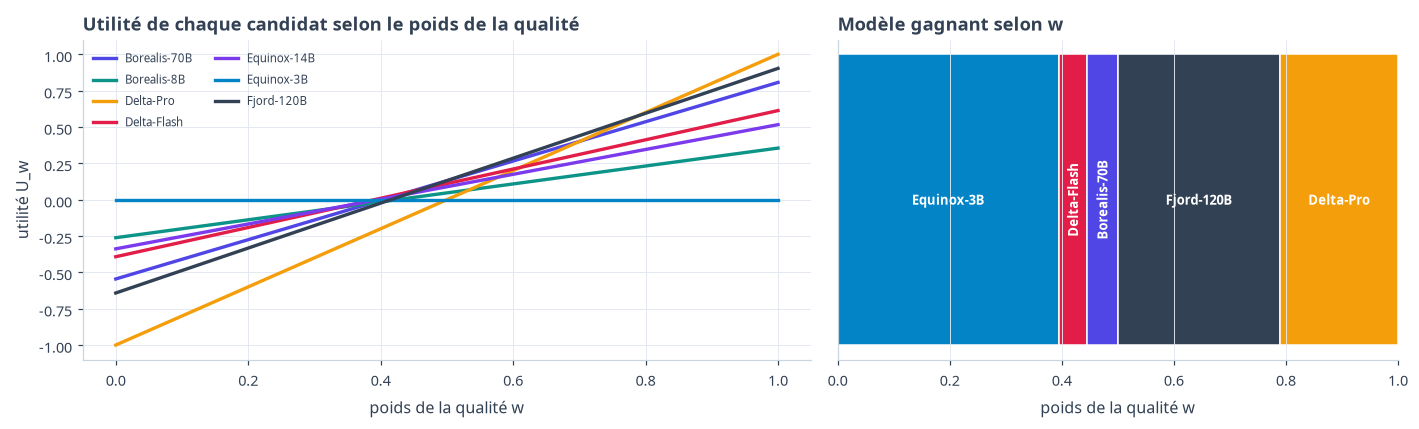

In [15]:
qn = (ok.qualite - ok.qualite.min()) / (ok.qualite.max() - ok.qualite.min())
lc = np.log(ok.prix_sortie)
cn = (lc - lc.min()) / (lc.max() - lc.min())
ws = np.linspace(0, 1, 201)
U = np.array([w * qn - (1 - w) * cn for w in ws])
winner = ok.modele.values[U.argmax(1)]
front = c4.pareto_front(ok.prix_sortie, ok.qualite)

fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw=dict(width_ratios=[1.3, 1]))
for i, mname in enumerate(ok.modele):
    axes[0].plot(ws, U[:, i], color=COLORS[i % len(COLORS)], lw=2.2 if front[i] else 1, ls="-" if front[i] else ":",
                 label=mname + ("" if front[i] else " (dominé)"))
axes[0].set_xlabel("poids de la qualité w"); axes[0].set_ylabel("utilité U_w")
axes[0].set_title("Utilité de chaque candidat selon le poids de la qualité"); axes[0].legend(fontsize=7.5, ncol=2)
changes = [0] + [i for i in range(1, len(ws)) if winner[i] != winner[i - 1]] + [len(ws) - 1]
for a, b in zip(changes[:-1], changes[1:]):
    c = COLORS[list(ok.modele).index(winner[a]) % len(COLORS)]
    axes[1].barh(0, ws[b] - ws[a], left=ws[a], color=c, edgecolor="white")
    axes[1].text((ws[a] + ws[b]) / 2, 0, winner[a], ha="center", va="center", color="white", fontsize=8.5,
                 fontweight="bold", rotation=90 if ws[b] - ws[a] < 0.12 else 0)
axes[1].set_yticks([]); axes[1].set_xlabel("poids de la qualité w"); axes[1].set_xlim(0, 1)
axes[1].set_title("Modèle gagnant selon w")
finish(fig)
jamais = sorted(set(ok.modele[front]) - set(winner))
print("modèles du front de Pareto qui ne gagnent pour aucun w :", jamais or "aucun")

Seuls des modèles du front de Pareto gagnent pour une valeur de $w$ (un modèle dominé, tracé en
pointillés s'il y en a, n'est jamais au-dessus) : c'est la propriété qui justifie de restreindre
la discussion au front. La réciproque est fausse : un modèle du front peut ne gagner pour
**aucun** $w$ (voir la ligne affichée) ; une utilité linéaire ne sélectionne que les modèles
situés sur l'**enveloppe convexe** du front. Pour les autres, il faut une utilité non linéaire
(par exemple un seuil de qualité minimal, puis le moins cher). Le choix de $w$ n'est pas technique : il traduit la valeur métier d'un
point de qualité (combien coûte une erreur de tri d'un courriel urgent ?). Pour un tri
médical, on prendra un $w$ élevé, puis on vérifiera le candidat retenu sur **ses propres
courriels annotés** (étape 3 du workflow).

> **À retenir.** Les attributs durs éliminent ; une utilité pondérée départage les survivants.
> Seuls les modèles du front de Pareto peuvent gagner, et le poids relatif qualité / coût est
> une décision métier à expliciter.

In [16]:
c4.load_nli.cache_clear()
llm.free_gpu()